# 12. Perbaikan fullpage dan evaluasi checkpoint

Notebook ini memperlihatkan eksperimen fullpage-v2 yang disetujui, training 3.600 update dengan exact resume, perbandingan checkpoint pada 1.800 dan 3.600, serta peta kegagalan development. Evaluasi menggunakan 80 request validasi yang sama. Target 95% berarti setidaknya 76 halaman lolos validator. Notebook ini tidak memuat training ulang dan tidak membuka data final.

## 1. Data, pemisahan, dan konfigurasi

Data tambahan hanya dibuat dari keluarga train. Validasi dan final disalin byte-identik dari v1. Kita membandingkan hash yang tercatat pada manifest dan tidak membaca baris request final.

In [1]:
from pathlib import Path
import hashlib, json
import pandas as pd
from IPython.display import display
ROOT = Path.cwd().resolve()
read = lambda p: json.loads((ROOT / p).read_text(encoding="utf-8"))
v1 = read("data/processed/fullpage/v1/manifest.json")
v2 = read("data/processed/fullpage/v2/manifest.json")
config = read("configs/fullpage/training-improvement-v2-r1.json")
heldout_names = ("validation.jsonl", "validation.requests.jsonl", "test.jsonl", "test.requests.jsonl")
heldout_same = all(v1["files"][name]["sha256"] == v2["files"][name]["sha256"] for name in heldout_names)
final_claim_present = (ROOT / "data/evaluation/fullpage/final_consumption.json").exists()
summary = {"train task rows": v2["task_counts"]["train"], "train plan rows": v2["augmentation"]["added_tasks"]["page_plan"] + 960, "train section rows": v2["task_counts"]["train"] - v2["augmentation"]["added_tasks"]["page_plan"] - 960, "train request variations": v2["augmentation"]["train_pages_added"], "train families": v2["family_counts"]["train"], "validation tasks": v2["task_counts"]["validation"], "heldout hashes unchanged": heldout_same, "final claim present": final_claim_present, "final request rows parsed": False, "plan batch probability": config["plan_batch_probability"], "training updates": config["max_steps"]}
display(pd.DataFrame([summary]).T.rename(columns={0:"Value"}))

,Value
train task rows,17280
train plan rows,4800
train section rows,12480
train request variations,1920
train families,240
validation tasks,960
heldout hashes unchanged,True
final claim present,False
final request rows parsed,False
plan batch probability,0.7


## 2. RTX 5070 dan pemilihan batch

Keempat ukuran microbatch diprofilkan dengan tugas fullpage-v2 dan rasio plan 70%. Batch 16 dipilih karena throughput terukur tertinggi sambil tetap stabil pada profil konteks terburuk 2.048 token.

In [2]:
import torch
profile = read("reports/training/FULLPAGE-GPU-003.json")
profile_rows = [{"batch": r["batch"], "accumulation": r["accumulation"], "effective batch": r["effective_batch"], "status": r["status"], "tokens per second": round(r["tokens_per_second"]), "peak allocated GiB": round(r["peak_allocated_bytes"] / 2**30, 2)} for r in profile["results"]]
print({"torch": torch.__version__, "CUDA build": torch.version.cuda, "CUDA available now": torch.cuda.is_available(), "GPU": torch.cuda.get_device_name() if torch.cuda.is_available() else None})
display(pd.DataFrame(profile_rows))

{'torch': '2.14.1+cu130', 'CUDA build': '13.0', 'CUDA available now': True, 'GPU': 'NVIDIA GeForce RTX 5070'}


,batch,accumulation,effective batch,status,tokens per second,peak allocated GiB
0,4,12,48,stable,46579,1.12
1,8,6,48,stable,50892,1.92
2,12,4,48,stable,55041,2.71
3,16,3,48,stable,55059,3.50


## 3. Training dan exact resume

TRAIN-018 memulai dari checkpoint INIT2048 pada step 0 dan berhenti sementara sesudah step 1.800. TRAIN-019 memulihkan optimizer, scheduler, sampler cursor, dan random state dari checkpoint penuh tersebut lalu melanjutkan ke step global 3.600 dengan hash konfigurasi yang sama.

In [3]:
runs = []
for run_id in ("TRAIN-018", "TRAIN-019"):
    r = read(f"reports/training/{run_id}.json")
    gpu = r.get("gpu_telemetry", {})
    runs.append({"run": run_id, "status": r["status"], "global step": r["global_step"], "best validation CE": r["best_validation_loss"], "final validation CE": r["final_validation"]["loss"], "target tokens": r["total_train_tokens"], "runtime seconds": round(r["wall_seconds"], 1), "GPU utilization mean %": round(gpu.get("utilization_pct", {}).get("mean", 0), 1), "GPU temperature max C": gpu.get("temperature_c", {}).get("max"), "peak VRAM allocated GiB": round(r["peak_allocated_bytes"] / 2**30, 2), "free disk GiB after": round(r["free_bytes_after"] / 2**30, 2), "config SHA": r["config_sha256"]})
display(pd.DataFrame(runs).set_index("run"))

,status,global step,best validation CE,final validation CE,target tokens,runtime seconds,GPU utilization mean %,GPU temperature max C,peak VRAM allocated GiB,free disk GiB after,config SHA
run,,,,,,,,,,,
TRAIN-018,stopped_at_limit,1800,0.012056,0.012056,29307745,566.7,92.2,70.0,3.51,16.02,d6476a9ee322255f8d0863074543946bd6fd80692cb873...
TRAIN-019,completed,3600,0.007519,0.007519,58725809,547.8,92.0,71.0,3.51,15.54,d6476a9ee322255f8d0863074543946bd6fd80692cb873...


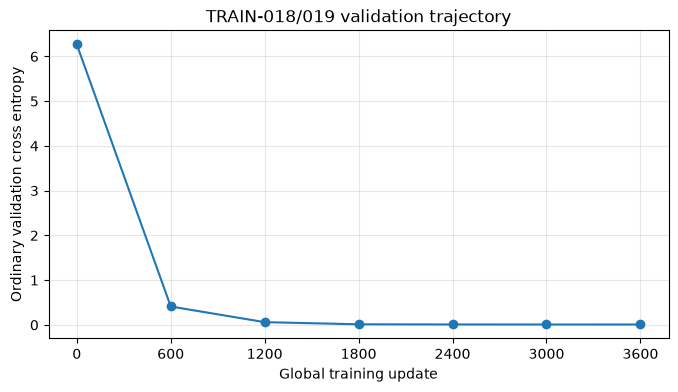

{'global updates plotted': [0, 600, 1200, 1800, 2400, 3000, 3600], 'initial CE': 6.266232563831536, 'step 1800 CE': 0.012055509651134822, 'step 3600 CE': 0.0075190683748171585}


In [4]:
import matplotlib.pyplot as plt
validation = {}
for run_id in ("TRAIN-018", "TRAIN-019"):
    path = ROOT / f"outputs/metrics/{run_id}.jsonl"
    for line in path.read_text(encoding="utf-8").splitlines():
        record = json.loads(line)
        if record.get("event") == "validation":
            validation[record["step"]] = record["loss"]
steps = sorted(validation)
plt.figure(figsize=(8, 4))
plt.plot(steps, [validation[s] for s in steps], marker="o")
plt.xticks(steps)
plt.xlabel("Global training update")
plt.ylabel("Ordinary validation cross entropy")
plt.title("TRAIN-018/019 validation trajectory")
plt.grid(True, alpha=.3)
plt.show()
print({"global updates plotted": steps, "initial CE": validation[0], "step 1800 CE": validation[1800], "step 3600 CE": validation[3600]})

## 4. Halaman development dan pemilihan checkpoint

Kelulusan dihitung dari halaman utuh yang lolos validator. Cross entropy hanya menjadi pemecah seri setelah jumlah halaman valid, cakupan role wajib, dan kelulusan pada percobaan pertama.

In [5]:
evaluation = []
for step, rel in ((1800, "reports/fullpage/TRAIN-018_DEVELOPMENT.json"), (3600, "reports/fullpage/TRAIN-019_DEVELOPMENT.json")):
    r = read(rel)
    evaluation.append({"step": step, "valid pages": r["complete"], "total": r["total"], "rate %": round(r["complete_rate"] * 100, 2), "required roles": r["required_roles"], "first attempt valid": r["first_attempt_complete"], "ordinary validation CE": round(validation[step], 6), "gate 76/80": r["model_gate"]})
display(pd.DataFrame(evaluation).set_index("step"))
selection = read("reports/fullpage/AI-019_DEVELOPMENT_SELECTION.json")
print({"selected step": selection["selected_step"], "selected checkpoint": selection["selected_checkpoint"], "gate passed": selection["development_gate_passed"], "final used": selection["final_used"]})

,valid pages,total,rate %,required roles,first attempt valid,ordinary validation CE,gate 76/80
step,,,,,,,
1800,46,80,57.5,46,46,0.012056,False
3600,70,80,87.5,70,70,0.007519,False


{'selected step': 3600, 'selected checkpoint': 'checkpoints/TRAIN-019/generation-3600.pt', 'gate passed': False, 'final used': False}


## 5. Peta kegagalan dan batas bukti

Kegagalan identik pada CSS biasa dan Tailwind berarti masalah request keluarga yang sama dapat memengaruhi dua ekspor. Kelulusan validator membuktikan kontrak lokal, bukan penilaian visual browser atau kebenaran semua klaim teks.

In [6]:
from collections import Counter
source_files = {1800: "reports/fullpage/TRAIN-018_DEVELOPMENT.json", 3600: "reports/fullpage/TRAIN-019_DEVELOPMENT.json"}
pass_ids, failed_ids, by_stage, by_category = {}, {}, {}, {}
for step, rel in source_files.items():
    report = read(rel); output = Path(report["output"])
    passed = {r["request_id"] for r in report["results"] if r["status"] == "accepted"}
    failed = {r["request_id"] for r in report["results"] if r["status"] != "accepted"}
    pass_ids[step], failed_ids[step] = passed, failed
    stage_counts, category_counts = Counter(), Counter()
    for request_id in failed:
        result = json.loads((output / request_id / "attempt-01" / "result.json").read_text(encoding="utf-8"))
        for attempt in result.get("attempts", []):
            for error in attempt.get("errors", []):
                stage_counts[attempt.get("stage", "unknown")] += 1
                low = error.lower()
                if "plan request identity/style mismatch" in low: category = "plan identity/style"
                elif "brand fact mismatch" in low: category = "navbar brand identity"
                elif "required fact item mismatch" in low: category = "required request fact item"
                elif "unprovided structured item" in low: category = "unsupported structured item"
                elif "required" in low or "field" in low or "schema" in low: category = "required field/schema"
                elif "fact" in low or "supplied" in low: category = "fact/content"
                else: category = error.split(":", 1)[0][:90]
                category_counts[category] += 1
    by_stage[step], by_category[step] = dict(stage_counts), dict(category_counts)
newly_valid = sorted(pass_ids[3600] - pass_ids[1800])
still_failed = sorted(failed_ids[3600] & failed_ids[1800])
print(json.dumps({"newly valid request outputs": len(newly_valid), "regressions": len(pass_ids[1800] - pass_ids[3600]), "still failed": len(still_failed), "step 3600 error attempts by stage": by_stage[3600], "step 3600 error categories": by_category[3600], "still failed IDs": still_failed, "final consumed": False}, indent=2))

{
  "newly valid request outputs": 24,
  "regressions": 0,
  "still failed": 10,
  "step 3600 error attempts by stage": {
    "nav": 4,
    "plan": 12,
    "faq": 10
  },
  "step 3600 error categories": {
    "navbar brand identity": 4,
    "plan identity/style": 12,
    "required request fact item": 6,
    "unsupported structured item": 4
  },
  "still failed IDs": [
    "page0247-plain_css",
    "page0247-tailwind",
    "page0249-plain_css",
    "page0249-tailwind",
    "page0252-plain_css",
    "page0252-tailwind",
    "page0253-plain_css",
    "page0253-tailwind",
    "page0271-plain_css",
    "page0271-tailwind"
  ],
  "final consumed": false
}


## Kesimpulan eksperimen

Snapshot update 3.600 mencapai 70/80 halaman valid, naik dari 46/80 pada update 1.800 dan dari baseline TRAIN-017 sebesar 58/80. Target 76/80 belum tercapai, jadi seleksi berstatus `needs_additional_improvement` dan final tetap tertutup. GPU/browser, review manusia, dan kualitas visual tidak dinilai notebook ini.

Langkah berikutnya perlu menargetkan kegagalan berulang pada identitas nama, field plan wajib, dan layanan atau klaim yang tidak punya fakta pendukung. Dataset WebMC tetap untuk evaluasi terpisah, bukan data training prompt-ke-halaman.